# Scores and diagnostic checks

Validate the forecast before interpreting its score. Use controlled faults to see which property each check can detect.

**Development notebook.** Expand the library cells to edit the implementation. Examples below use local data and CPU. [Build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp metrics

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'pyproject.toml').is_file() and (p / 'timegym').is_dir())
plt.style.use('default')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110,
    'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})

## Build `metrics`

### Imports and configuration

In [3]:
#| export metrics
from __future__ import annotations
from timegym._internal import positive_int, _real_array

import numpy as np

### UndefinedMetricError — A score is undefined for the supplied, otherwise valid, data.

In [4]:
#| export metrics
class UndefinedMetricError(ValueError):
    """A score is undefined for the supplied, otherwise valid, data."""

### _array

In [5]:
#| export metrics
def _array(value, name):
    array = _real_array(value, name)
    if array.ndim == 0 or array.size == 0:
        raise ValueError(f"{name} must be a nonempty array")
    if not np.all(np.isfinite(array)):
        raise ValueError(f"{name} must contain only finite numbers")
    return array

### _pair

In [6]:
#| export metrics
def _pair(observed, predicted):
    observed = _array(observed, "observed")
    predicted = _array(predicted, "predicted")
    if observed.shape != predicted.shape:
        raise ValueError("observed and predicted must have identical shapes")
    return observed, predicted

### _ensemble

In [7]:
#| export metrics
def _ensemble(observed, samples):
    observed = _array(observed, "observed")
    samples = _array(samples, "samples")
    if samples.ndim != observed.ndim + 1 or samples.shape[1:] != observed.shape:
        raise ValueError("samples must have shape (n_samples, *observed.shape)")
    return observed, samples

### mse — Mean squared error over observation coordinates.

In [8]:
#| export metrics
def mse(observed, predicted):
    """Mean squared error over observation coordinates."""
    observed, predicted = _pair(observed, predicted)
    return float(np.mean((observed - predicted) ** 2))

### mae — Mean absolute error over observation coordinates.

In [9]:
#| export metrics
def mae(observed, predicted):
    """Mean absolute error over observation coordinates."""
    observed, predicted = _pair(observed, predicted)
    return float(np.mean(np.abs(observed - predicted)))

### mean_reference_mse — Squared distance from a supplied conditional mean, not generic regret.

In [10]:
#| export metrics
def mean_reference_mse(reference_mean, predicted):
    """Squared distance from a supplied conditional mean, not generic regret.

    With a valid conditional mean this is the conditional excess squared-error
    risk, averaged over coordinates. It is not realised loss against a future
    observation and is not a reference for other losses.
    """
    return mse(reference_mean, predicted)

### mase — MASE, scaling each target by its in-context seasonal naive MAE.

In [11]:
#| export metrics
def mase(observed, predicted, context, seasonality=1):
    """MASE, scaling each target by its in-context seasonal naive MAE.

    Time is axis zero. A constant target or insufficient history makes the
    aggregate undefined and raises :class:`UndefinedMetricError`; no epsilon
    denominator or omission of constant targets is silently introduced.
    """
    observed, predicted = _pair(observed, predicted)
    context = _array(context, "context")
    seasonality = positive_int(seasonality, 'seasonality')
    if context.ndim != observed.ndim or context.shape[1:] != observed.shape[1:]:
        raise ValueError("context and observed must have identical non-time dimensions")
    if len(context) <= seasonality:
        raise UndefinedMetricError("MASE needs more context observations than seasonality")
    scale = np.mean(np.abs(context[seasonality:] - context[:-seasonality]), axis=0)
    if np.any(scale == 0):
        raise UndefinedMetricError("MASE is undefined for a zero naive-error denominator")
    return float(np.mean(np.abs(observed - predicted) / scale))

### pinball — Mean quantile (pinball) loss, without the optional factor of two.

In [12]:
#| export metrics
def pinball(observed, quantiles, levels):
    """Mean quantile (pinball) loss, without the optional factor of two."""
    observed = _array(observed, "observed")
    quantiles = _array(quantiles, "quantiles")
    levels = _array(levels, "levels")
    if levels.ndim != 1 or np.any((levels <= 0) | (levels >= 1)) or np.any(np.diff(levels) <= 0):
        raise ValueError("levels must be strictly increasing values in (0, 1)")
    if quantiles.shape != observed.shape + (len(levels),):
        raise ValueError("quantiles must have shape (*observed.shape, n_levels)")
    if np.any(quantiles[..., 1:] < quantiles[..., :-1]):
        raise ValueError("quantiles must not cross")
    residual = observed[..., None] - quantiles
    return float(np.mean(np.maximum(levels * residual, (levels - 1) * residual)))

### crps — Mean marginal CRPS of the finite empirical ensemble distribution.

In [13]:
#| export metrics
def crps(observed, samples):
    """Mean marginal CRPS of the finite empirical ensemble distribution.

    Computes E|X-y| - E|X-X'|/2 with replacement, including diagonal pairs.
    The sorted formula is O(S log S) per coordinate, not O(S squared).
    This is the empirical-distribution score, not the fair-ensemble estimator.
    """
    observed, samples = _ensemble(observed, samples)
    n_samples = samples.shape[0]
    ordered = np.sort(samples, axis=0)
    coefficients = (2 * np.arange(1, n_samples + 1) - n_samples - 1).reshape(
        (n_samples,) + (1,) * observed.ndim
    )
    # Coefficients sum to zero. Centering avoids cancellation when all draws
    # share a large location offset compared with their spread.
    half_pairwise = np.sum(coefficients * (ordered - ordered[:1]), axis=0) / n_samples**2
    return float(np.mean(np.mean(np.abs(samples - observed), axis=0) - half_pairwise))

### energy_score — Energy score of the entire horizon-target vector using Euclidean norm.

In [14]:
#| export metrics
def energy_score(observed, samples, chunk_size=128):
    """Energy score of the entire horizon-target vector using Euclidean norm.

    Pairwise distances are evaluated in chunks to bound memory. Like ``crps``,
    this scores the empirical distribution and includes diagonal sample pairs.
    The vector norm is not divided by the number of coordinates.
    """
    observed, samples = _ensemble(observed, samples)
    chunk_size = positive_int(chunk_size, 'chunk_size')
    vectors = samples.reshape(samples.shape[0], -1)
    target = observed.reshape(-1)
    first = np.mean(np.linalg.norm(vectors - target, axis=1))
    pair_sum = 0.0
    for i in range(0, len(vectors), chunk_size):
        left = vectors[i:i + chunk_size]
        for j in range(0, len(vectors), chunk_size):
            right = vectors[j:j + chunk_size]
            pair_sum += float(np.sum(np.linalg.norm(left[:, None, :] - right[None, :, :], axis=-1)))
    return float(first - pair_sum / (2 * len(vectors)**2))

### variogram_score — Mean squared variogram discrepancy across unordered coordinate pairs.

In [15]:
#| export metrics
def variogram_score(observed, samples, exponent=0.5):
    """Mean squared variogram discrepancy across unordered coordinate pairs.

    Horizon and target axes are flattened together. All distinct pairs receive
    equal weight and the sum is divided by their count. This explicitly fixes
    the normalization, which otherwise varies between score implementations.
    """
    observed, samples = _ensemble(observed, samples)
    if not np.isfinite(exponent) or not 0 < exponent < 2:
        raise ValueError("exponent must be finite and in (0, 2)")
    target = observed.reshape(-1)
    vectors = samples.reshape(samples.shape[0], -1)
    if len(target) < 2:
        raise UndefinedMetricError("variogram score needs at least two coordinates")
    total = 0.0
    count = 0
    # Looping over one coordinate bounds intermediate memory at O(S * K).
    for i in range(len(target) - 1):
        expected = np.mean(np.abs(vectors[:, i, None] - vectors[:, i + 1:]) ** exponent, axis=0)
        realised = np.abs(target[i] - target[i + 1:]) ** exponent
        total += float(np.sum((realised - expected) ** 2))
        count += len(realised)
    return total / count


# Explicit names are convenient when comparing marginal and joint scores.
empirical_crps = crps

In [ ]:
#| export statistics
from __future__ import annotations

from collections.abc import Sequence
import numpy as np
from scipy.stats import norm, t


def wilson_interval(values: Sequence[bool]) -> dict:
    """Wilson 95% interval across independent binary observations."""
    values = np.asarray(values)
    if values.ndim != 1 or values.size == 0 or not np.isin(values, [0, 1]).all():
        raise ValueError("A rate requires a nonempty vector of binary observations")
    count, n = int(values.sum()), len(values)
    p, z = count / n, float(norm.ppf(.975))
    center = (p + z*z/(2*n)) / (1 + z*z/n)
    radius = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return {"count": count, "n": n, "rate": p,
            "ci95": [float(max(0, center-radius)), float(min(1, center+radius))]}


def paired_t_interval(values: Sequence[float]) -> dict:
    """Student t 95% interval for the mean of independent paired differences.

    Supply one difference per independent case, not dependent coordinates.
    Constant differences yield a zero-width interval; this is not a binary
    proportion-difference interval.
    """
    values = np.asarray(values, dtype=float)
    if values.ndim != 1 or len(values) < 2 or not np.isfinite(values).all():
        raise ValueError("A paired mean interval requires at least two finite cases in a vector")
    center = float(values.mean())
    half = float(t.ppf(.975, len(values)-1) * values.std(ddof=1) / np.sqrt(len(values)))
    return {"mean": center, "n": len(values), "ci95": [center-half, center+half]}


## Build `diagnostics`

### Imports and configuration

In [16]:
# Development-only binding for the metric module defined in this chapter.
# Exported diagnostics still import timegym.metrics normally. A namespace here
# lets local diagnostics exercise local metric edits without changing modules.
from types import SimpleNamespace
_notebook_metrics = SimpleNamespace(
    UndefinedMetricError=UndefinedMetricError,
    _array=_array, _pair=_pair, _ensemble=_ensemble,
    mse=mse, mae=mae, mase=mase, mean_reference_mse=mean_reference_mse,
    pinball=pinball, crps=crps, empirical_crps=empirical_crps,
    energy_score=energy_score, variogram_score=variogram_score,
)

In [17]:
#| export diagnostics
from __future__ import annotations
from timegym._internal import nonnegative_int, _exception_evidence

import math

import numpy as np

from timegym import metrics
from timegym.contracts import SimulationReference
from timegym.reporting import CaseResult, DiagnosticResult
from timegym.provenance import diagnostic_settings


### exception_evidence — Keep errors inspectable in a report instead of counting them as passes.

In [18]:
#| export diagnostics
def exception_evidence(exc):
    """Keep errors inspectable in a report instead of counting them as passes."""
    return _exception_evidence(exc)


### covariance_dependence_check — Monte Carlo check of an ensemble's covariance against a known law.

In [19]:
#| export diagnostics
def covariance_dependence_check(reference, samples, *, seed=0, n_calibration=99, alpha=0.05):
    """Monte Carlo check of an ensemble's covariance against a known law.

    Flatten horizon and target axes in C order. The discrepancy is the
    Frobenius distance between unbiased sample covariance and reference
    covariance, divided by the latter's Frobenius norm. Calibration ensembles
    have the same sample count as the forecast. The rank p-value is
    ``(1 + # calibration statistics >= observed) / (B + 1)``; ties are
    conservative. This tests covariance consistency under iid draws from the
    specified reference, not general calibration or a causal fault mechanism.
    Variance errors can also trigger this check. Alpha is per check, without
    automatic adjustment across multiple cases. A numerical covariance target
    remains fixed across the observed and null statistics; its Monte Carlo
    stream must be independent of every ensemble used in rank calibration.
    """
    name, category = "reference_covariance", "distribution"
    seed = nonnegative_int(seed, "seed")
    settings = diagnostic_settings(n_calibration=n_calibration, alpha=alpha)
    n_calibration, alpha = settings["n_calibration"], settings["alpha"]
    if samples is None or reference is None or getattr(reference, "covariance", None) is None:
        return DiagnosticResult(name, "UNSUPPORTED", category, "Predictive samples and a reference covariance are required.")
    if isinstance(reference, SimulationReference) and reference.sampler_kind != "exact_conditional":
        return DiagnosticResult(name, "UNSUPPORTED", category,
                                "An approximate reference simulator cannot calibrate an exact conditional-law diagnostic.",
                                {"reference": {"kind": reference.kind, **reference.capabilities}})
    samples = metrics._array(samples, "samples")
    expected_shape = metrics._array(reference.mean, "reference mean").shape
    if samples.ndim != 3 or samples.shape[1:] != expected_shape:
        raise ValueError("samples must have shape (n_samples, *reference.mean.shape)")
    n_samples = len(samples)
    n_coordinates = int(np.prod(expected_shape))
    if n_coordinates < 2:
        return DiagnosticResult(name, "UNSUPPORTED", category,
                                "Dependence comparison requires at least two coordinates.",
                                {"n_samples": n_samples, "n_coordinates": n_coordinates})
    if n_samples < 20:
        return DiagnosticResult(name, "INCONCLUSIVE", category, "Covariance comparison requires at least 20 samples.",
                                {"n_samples": n_samples, "n_coordinates": n_coordinates})
    covariance = metrics._array(reference.covariance, "reference covariance")
    if covariance.shape != (n_coordinates, n_coordinates):
        raise ValueError("reference covariance must match the flattened trajectory")
    scale = np.linalg.norm(covariance, ord="fro")
    if scale == 0:
        return DiagnosticResult(name, "UNSUPPORTED", category, "Normalized covariance comparison is undefined for a deterministic reference.")

    def statistic(draw):
        vectors = draw.reshape(n_samples, n_coordinates)
        centered = vectors - vectors.mean(axis=0)
        empirical = centered.T @ centered / (n_samples - 1)
        value = float(np.linalg.norm(empirical - covariance, ord="fro") / scale)
        if not np.isfinite(value):
            raise ValueError("covariance discrepancy is numerically nonfinite")
        return value

    observed = statistic(samples)
    rng = np.random.default_rng(seed)
    null_statistics = []
    # Bound calibration draws to roughly one million values per batch while
    # avoiding a new reference matrix factorization for every ensemble.
    batch_size = max(1, min(n_calibration, 1_000_000 // (n_samples * n_coordinates)))
    for first in range(0, n_calibration, batch_size):
        batch_count = min(batch_size, n_calibration - first)
        batch_seed = int(rng.integers(0, np.iinfo(np.int64).max))
        draws = metrics._array(reference.sample(batch_count * n_samples, batch_seed), "reference calibration draws")
        if draws.shape != (batch_count * n_samples,) + expected_shape:
            raise ValueError("reference sampler returned invalid calibration draws")
        draws = draws.reshape(batch_count, n_samples, *expected_shape)
        null_statistics.extend(statistic(draw) for draw in draws)
    null_statistics = np.asarray(null_statistics)
    p_value = float((1 + np.sum(null_statistics >= observed)) / (n_calibration + 1))
    rank = math.ceil((n_calibration + 1) * (1 - alpha))
    critical_value = float(np.sort(null_statistics)[rank - 1]) if rank <= n_calibration else None
    evidence = {
        "statistic": observed,
        "statistic_name": "normalized_covariance_frobenius_error",
        "p_value": p_value,
        "alpha": float(alpha),
        "n_calibration": int(n_calibration),
        "critical_value": critical_value,
        "minimum_p_value": 1 / (n_calibration + 1),
        "n_samples": n_samples,
        "n_coordinates": n_coordinates,
        "seed": seed,
        "null": "iid draws from the specified conditional reference law",
        "multiplicity": "per-check alpha; no correction across cases",
    }
    if isinstance(reference, SimulationReference):
        evidence["reference"] = {"kind": reference.kind, **reference.capabilities}
        if reference.moments_kind == "analytic_mean_monte_carlo_covariance":
            evidence["covariance_target"] = "fixed_independently_estimated_covariance; exact_sampler_rank_calibration"
    if 1 / (n_calibration + 1) > alpha:
        return DiagnosticResult(name, "INCONCLUSIVE", category, "Too few calibration ensembles to reject at the requested alpha.", evidence)
    rejected = p_value <= alpha
    message = ("Ensemble covariance differs from the specified reference at the declared per-check level."
               if rejected else "No covariance discrepancy detected at the declared level; this does not establish equality of distributions.")
    return DiagnosticResult(name, "FAIL" if rejected else "PASS", category, message, evidence)

### evaluate_forecast — Validate a forecast and record scores without inventing pass thresholds.

In [20]:
#| export diagnostics
def evaluate_forecast(case, forecast, *, check_dependence=False, dependence_seed=0, n_calibration=99, alpha=0.05):
    """Validate a forecast and record scores without inventing pass thresholds.

    Malformed forecasts are rejected before scoring. Missing point, quantile,
    or ensemble outputs are UNSUPPORTED, not reconstructed from other output
    types. A known-mean discrepancy and one-path interval coverage are
    descriptive evidence and are INCONCLUSIVE as capability decisions.
    """
    dependence_seed = nonnegative_int(dependence_seed, "dependence_seed")
    settings = diagnostic_settings(check_dependence=check_dependence,
                                   n_calibration=n_calibration, alpha=alpha)
    n_calibration, alpha = settings["n_calibration"], settings["alpha"]
    manifest = dict(case.manifest)
    result = CaseResult(str(manifest["kind"]), manifest["seed"], manifest=manifest)
    try:
        violations = forecast.validate(case.task)
    except Exception as exc:
        result.diagnostics.append(DiagnosticResult("forecast_contract", "ERROR", "correctness", "Forecast contract validation raised an exception.", exception_evidence(exc)))
        return result
    if violations:
        result.diagnostics.extend(DiagnosticResult("contract_" + str(item["code"]), "FAIL", "correctness", str(item["message"]), {"code": item["code"]}) for item in violations)
        return result
    result.diagnostics.append(DiagnosticResult("forecast_contract", "PASS", "correctness", "Forecast indices, target order, shapes, finiteness, and quantile order satisfy the declared contract."))

    def score(name, function, *args, **kwargs):
        try:
            value = function(*args, **kwargs)
            if not np.isfinite(value):
                raise ValueError("score calculation returned a nonfinite value")
            result.metrics[name] = float(value)
        except metrics.UndefinedMetricError as exc:
            result.diagnostics.append(DiagnosticResult("metric_" + name, "INCONCLUSIVE", "capability", str(exc), {"reason": "undefined_metric"}))
        except Exception as exc:
            result.diagnostics.append(DiagnosticResult("metric_" + name, "ERROR", "capability", "Score calculation raised an exception.", exception_evidence(exc)))

    try:
        observed = metrics._array(case.observed.to_numpy(), "observed")
        expected_shape = (len(case.task.future_index), len(case.task.target_names))
        if observed.shape != expected_shape:
            raise ValueError("held-out observations must match the forecast task")
        if not case.observed.index.equals(case.task.future_index) or tuple(case.observed.columns) != case.task.target_names:
            raise ValueError("held-out observations must have the requested index and target order")
    except Exception as exc:
        result.diagnostics.append(DiagnosticResult("evaluation_data", "ERROR", "evaluation", "Held-out data do not satisfy the evaluation contract.", exception_evidence(exc)))
        return result

    if case.reference is not None:
        try:
            reference = case.reference
            reference.validate()
            if not reference.index.equals(case.task.future_index) or tuple(reference.target_names) != case.task.target_names:
                raise ValueError("reference index and target order must match the forecast task")
        except Exception as exc:
            result.diagnostics.append(DiagnosticResult("evaluation_reference", "ERROR", "evaluation", "Reference does not satisfy the evaluation contract.", exception_evidence(exc)))
            return result

    def descriptive(name, message, score_names, **details):
        evidence = {key: result.metrics[key] for key in score_names if key in result.metrics}
        evidence.update(details)
        if isinstance(case.reference, SimulationReference):
            evidence["reference"] = {"kind": case.reference.kind, **case.reference.capabilities}
        result.diagnostics.append(DiagnosticResult(name, "INCONCLUSIVE", "capability", message, evidence))

    if forecast.point is None:
        result.diagnostics.append(DiagnosticResult("point_accuracy", "UNSUPPORTED", "capability", "No explicit point forecast was supplied."))
    else:
        score("mse", metrics.mse, observed, forecast.point)
        score("mae", metrics.mae, observed, forecast.point)
        score("mase", metrics.mase, observed, forecast.point, case.task.context.to_numpy(), seasonality=1)
        if case.reference is not None:
            score("mean_reference_mse", metrics.mean_reference_mse, case.reference.mean, forecast.point)
        descriptive("point_accuracy",
                    "Point scores are descriptive; no capability acceptance tolerance was declared.",
                    ("mse", "mae", "mase", "mean_reference_mse"), mase_seasonality=1)


    if forecast.quantiles is None:
        result.diagnostics.append(DiagnosticResult("quantile_accuracy", "UNSUPPORTED", "capability", "No explicit quantile forecasts were supplied."))
    else:
        score("pinball", metrics.pinball, observed, forecast.quantiles, forecast.levels)
        descriptive("quantile_accuracy",
                    "Quantile loss is descriptive; no capability acceptance tolerance was declared.",
                    ("pinball",))
        if len(forecast.levels) >= 2:
            quantiles = metrics._array(forecast.quantiles, "quantiles")
            coverage = float(np.mean((observed >= quantiles[..., 0]) & (observed <= quantiles[..., -1])))
            nominal = float(forecast.levels[-1] - forecast.levels[0])
            result.metrics.update(interval_coverage=coverage, interval_nominal_coverage=nominal)

            def interval_width():
                # Scale each nonnegative width contribution before summing so
                # a representable mean is not lost to an overflowing total.
                count = quantiles[..., 0].size
                with np.errstate(over="raise", invalid="raise"):
                    return float(np.sum(quantiles[..., -1] / count - quantiles[..., 0] / count))

            score("interval_width", interval_width)
            evidence = {"observed_coverage": coverage, "nominal_coverage": nominal,
                        "lower_level": float(forecast.levels[0]), "upper_level": float(forecast.levels[-1])}
            if "interval_width" in result.metrics:
                evidence["mean_width"] = result.metrics["interval_width"]
            result.diagnostics.append(DiagnosticResult("interval_coverage", "INCONCLUSIVE", "uncertainty", "One-path coverage across possibly dependent coordinates does not establish calibration.", evidence))
        else:
            result.diagnostics.append(DiagnosticResult("interval_coverage", "UNSUPPORTED", "uncertainty", "At least two explicit quantile levels are needed to form an interval."))

    if forecast.samples is None:
        result.diagnostics.append(DiagnosticResult("sample_scores", "UNSUPPORTED", "capability", "No joint predictive samples were supplied."))
    else:
        score("crps", metrics.crps, observed, forecast.samples)
        score("energy_score", metrics.energy_score, observed, forecast.samples)
        score("variogram_score", metrics.variogram_score, observed, forecast.samples)
        descriptive("sample_scores",
                    "Empirical marginal and joint scores are descriptive; no capability acceptance tolerance was declared.",
                    ("crps", "energy_score", "variogram_score"))

    if check_dependence:
        try:
            result.diagnostics.append(covariance_dependence_check(case.reference, forecast.samples, seed=dependence_seed,
                                                                 n_calibration=n_calibration, alpha=alpha))
        except Exception as exc:
            result.diagnostics.append(DiagnosticResult("reference_covariance", "ERROR", "distribution", "Covariance comparison raised an exception.", exception_evidence(exc)))
    return result

## Build `checks`

### Imports and configuration

In [21]:
_notebook_exception_evidence = exception_evidence

In [22]:
#| export checks
import numpy as np
from timegym.contracts import ForecastTask
from timegym.reporting import DiagnosticResult
from timegym.diagnostics import exception_evidence

### check_shift_equivariance — Check f(y+c)=f(y)+c for a model declaring location equivariance.

In [23]:
#| export checks
def check_shift_equivariance(pipeline, context, future_index, *, shift=10.0, atol=1e-8, rtol=1e-7):
    """Check f(y+c)=f(y)+c for a model declaring location equivariance.

    This property is not universal: regularization, clipping or absolute features
    may intentionally violate it. Callers choose whether it applies to their model.
    """
    if not np.isfinite(shift) or shift == 0:
        raise ValueError("shift must be finite and nonzero")
    if not np.isfinite(atol) or not np.isfinite(rtol) or atol < 0 or rtol < 0:
        raise ValueError("atol and rtol must be finite and nonnegative")
    try:
        original = pipeline.predict(context, future_index)
        shifted = pipeline.predict(context + shift, future_index)
        violations = original.validate(ForecastTask(context, future_index)) + shifted.validate(
            ForecastTask(context + shift, future_index))
        if violations:
            return DiagnosticResult("shift_equivariance", "ERROR", "metamorphic",
                                    "Forecast contract must hold before comparing transformed outputs.",
                                    {"violations": violations})
        if original.point is None or shifted.point is None:
            return DiagnosticResult("shift_equivariance", "UNSUPPORTED", "metamorphic",
                                    "This check requires explicit mean point forecasts.", {})
        original_point = np.asarray(original.point, dtype=float)
        shifted_point = np.asarray(shifted.point, dtype=float)
        error = float(np.max(np.abs(shifted_point - original_point - shift)))
        passed = bool(np.allclose(shifted_point, original_point + shift, atol=atol, rtol=rtol))
        return DiagnosticResult("shift_equivariance", "PASS" if passed else "FAIL", "metamorphic",
                                "Declared location-equivariance relation tested on paired contexts.",
                                {"shift": shift, "max_absolute_error": error, "atol": atol, "rtol": rtol})
    except Exception as exc:
        return DiagnosticResult("shift_equivariance", "ERROR", "metamorphic",
                                f"{type(exc).__name__}: {exc}", exception_evidence(exc))

## Build `mutations`

### Imports and configuration

In [24]:
#| export mutations
from __future__ import annotations
from collections.abc import Callable
from copy import deepcopy
import numpy as np
import pandas as pd
from timegym.contracts import Forecast
from timegym._internal import nonnegative_int, _real_array


### mutate_forecast — Return a copy with one known fault; enabled=False is its paired repair.

In [25]:
#| export mutations
def _integer_index(result):
    if not pd.api.types.is_integer_dtype(result.index.dtype):
        raise ValueError("index_shift fixture requires an integer index")


def _multiple_targets(result):
    if len(result.target_names) < 2:
        raise ValueError("target_swap requires two or more targets")


def _point_output(result):
    if result.point is None or result.point.size == 0:
        raise ValueError("nonfinite_point requires explicit nonempty point forecasts")


def _ordered_quantiles(result):
    if (result.quantiles is None or result.quantiles.shape[-1] < 2
            or not np.any(np.diff(result.quantiles, axis=-1) > 0)):
        raise ValueError("quantile_crossing requires at least two distinct ordered quantiles")


def _unequal_sample_axes(result):
    if result.samples is None or result.samples.shape[0] == result.samples.shape[1]:
        raise ValueError("sample_axis_swap requires samples with sample count different from horizon")


def _all_outputs(result):
    if result.point is None or result.samples is None or result.quantiles is None:
        raise ValueError("variance_shrink requires point, sample, and quantile outputs")


def _sample_output(result):
    if result.samples is None:
        raise ValueError("dependence_shuffle requires predictive samples")


def _index_shift(result, rng, strength):
    """Shift an integer forecast index forward by one.

    Requires an integer index; ignores rng and strength.
    """
    result.index = result.index + 1


def _target_swap(result, rng, strength):
    """Reverse target labels without moving the forecast values.

    Requires at least two targets; ignores rng and strength.
    """
    result.target_names = tuple(reversed(result.target_names))


def _horizon_truncation(result, rng, strength):
    """Drop the final horizon from the index and every supplied output.

    Has no additional precondition; ignores rng and strength.
    """
    result.index = result.index[:-1]
    for attr in ("point", "quantiles"):
        value = getattr(result, attr)
        if value is not None:
            setattr(result, attr, value[:-1])
    if result.samples is not None:
        result.samples = result.samples[:, :-1]


def _nonfinite_point(result, rng, strength):
    """Replace the first point forecast with NaN.

    Requires nonempty explicit points; ignores rng and strength.
    """
    result.point[0, 0] = np.nan


def _quantile_crossing(result, rng, strength):
    """Reverse the quantile axis while keeping the declared levels.

    Requires distinct ordered quantiles; ignores rng and strength.
    """
    result.quantiles = result.quantiles[..., ::-1].copy()


def _sample_axis_swap(result, rng, strength):
    """Transpose the sample and horizon axes.

    Requires different sample and horizon counts; ignores rng and strength.
    """
    result.samples = result.samples.transpose(1, 0, 2)


def _variance_shrink(result, rng, strength):
    """Scale sample and quantile deviations by 1 - 0.75 * strength.

    Requires point, sample, and quantile outputs; ignores rng.
    """
    if strength == 0:
        return
    factor = 1 - 0.75 * strength
    result.samples = result.point[None] + factor * (result.samples - result.point[None])
    result.quantiles = result.point[..., None] + factor * (result.quantiles - result.point[..., None])


def _dependence_shuffle(result, rng, strength):
    """Independently permute a fraction of samples in each coordinate.

    Requires samples; rng and strength control permutations, preserving marginals.
    """
    count, horizon, targets = result.samples.shape
    selected = int(round(count * strength))
    for i in range(horizon):
        for j in range(targets):
            indices = rng.choice(count, selected, replace=False)
            result.samples[indices, i, j] = result.samples[rng.permutation(indices), i, j]


_FIXTURES: dict[str, tuple[Callable | None, Callable]] = {
    "index_shift": (_integer_index, _index_shift),
    "target_swap": (_multiple_targets, _target_swap),
    "horizon_truncation": (None, _horizon_truncation),
    "nonfinite_point": (_point_output, _nonfinite_point),
    "quantile_crossing": (_ordered_quantiles, _quantile_crossing),
    "sample_axis_swap": (_unequal_sample_axes, _sample_axis_swap),
    "variance_shrink": (_all_outputs, _variance_shrink),
    "dependence_shuffle": (_sample_output, _dependence_shuffle),
}
MUTATIONS = tuple(_FIXTURES)


def mutate_forecast(forecast: Forecast, name: str, *, seed=0, enabled=True, strength=1.0) -> Forecast:
    """Copy, coerce, and validate a fixture before optionally applying its fault.

    The bypass is the same prepared copy with the fault disabled. Strength in
    [0, 1] controls variance shrinkage and the fraction of shuffled samples;
    seed controls only shuffling. Other fixtures ignore these two controls.
    """
    if name not in _FIXTURES:
        raise ValueError(f"Unknown mutation: {name}")
    if not 0 <= strength <= 1:
        raise ValueError("strength must be between zero and one")
    seed = nonnegative_int(seed, "seed")
    result = deepcopy(forecast)
    for attr in ("point", "quantiles", "samples"):
        value = getattr(result, attr)
        if value is not None:
            setattr(result, attr, _real_array(value, attr).copy())
    precondition, fixture = _FIXTURES[name]
    if precondition is not None:
        precondition(result)
    if enabled:
        fixture(result, np.random.default_rng(seed), strength)
    return result


## A forecast can be well formed and badly located

In [26]:
# Restore live same-chapter dependencies after the export-oriented imports.
metrics = _notebook_metrics
exception_evidence = _notebook_exception_evidence
assert metrics.mse is mse
assert metrics.UndefinedMetricError is UndefinedMetricError
assert evaluate_forecast.__globals__['metrics'].mse is mse
assert exception_evidence.__module__ == evaluate_forecast.__module__ == __name__

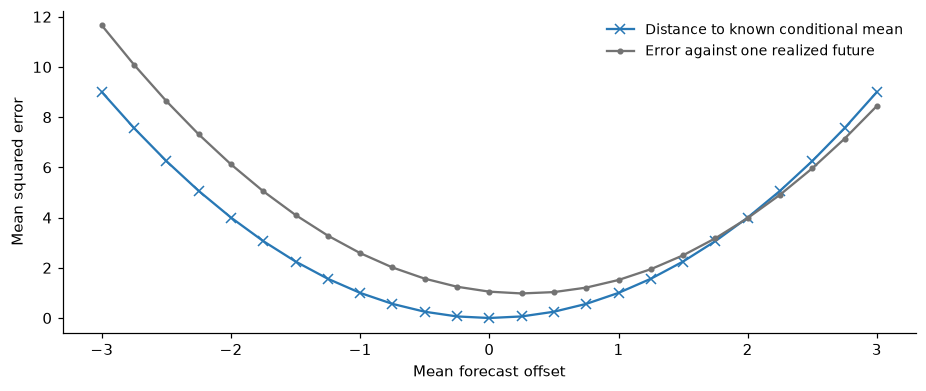

,name,status,message
0,contract_quantile_crossing,FAIL,Predicted quantiles decrease as the probabilit...


In [27]:
from timegym import Scenario, Forecast
case = Scenario('white_noise', context_length=120, horizon=24,
                parameters={'mean': 5., 'sigma': 1.}).generate(seed=3)
offsets = np.linspace(-3, 3, 25)
records = []
for offset in offsets:
    point = case.reference.mean + offset
    records.append((mean_reference_mse(case.reference.mean, point), mse(case.observed.to_numpy(), point)))
values = np.asarray(records)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(offsets, values[:, 0], color='#2878b5', marker='x', label='Distance to known conditional mean')
ax.plot(offsets, values[:, 1], color='.45', marker='.', label='Error against one realized future')
ax.set(xlabel='Mean forecast offset', ylabel='Mean squared error')
ax.legend(fontsize=9)
plt.show()
fixture = case.reference.forecast(n_samples=64, seed=12)
clean_result = evaluate_forecast(case, fixture)
assert not any(d.status == 'ERROR' for d in clean_result.diagnostics)
np.testing.assert_allclose(clean_result.metrics['mse'], mse(case.observed.to_numpy(), fixture.point))
assert clean_result.metrics['mean_reference_mse'] == 0.0
crossed = mutate_forecast(fixture, 'quantile_crossing')
bad_result = evaluate_forecast(case, crossed)
assert not bad_result.metrics
assert any(d.status == 'FAIL' for d in bad_result.diagnostics)
display(pd.DataFrame([d.to_dict() for d in bad_result.diagnostics])[['name', 'status', 'message']])

The empirical optimum may shift with the realized noise. Contract errors are rejected before scoring; poor descriptive scores do not identify a unique software fault. [Univariate](20_univariate_uncertainty.ipynb) and [joint](22_multivariate_uncertainty.ipynb) uncertainty demonstrations extend this comparison.

## Edit, run, export

After editing a source cell, **restart this kernel and Run All**. This refreshes the local definitions, the development bindings between modules in this chapter, and the nearby examples. Ordinary Run All does not export files.

Changes to code owned by another chapter require saving that source notebook, running `python tools/export_notebooks.py`, and restarting this kernel before importing the updated package. Runtime provenance describes the exported package, not unexported edits.

Try one implementation or parameter change, rerun this chapter, and inspect the figure or assertion. Save the notebook before exporting.